# Gold forecasting with LSTM

A compact LSTM uses the same data, output targets, folds and initial search budget as GRU.
Only the recurrent cell differs. Each fold starts with fresh weights and fresh fitted preprocessing.
The small initial architecture is deliberate because this dataset contains only a few thousand daily prices.

Run notebook 01 first. Review the shared audit and release assumptions before interpreting errors.

**SHORT WORKFLOW TEST ONLY:** one outer fold, one external-feature candidate; two maximum neural epochs / ten XGBoost trees. Not a forecasting-quality experiment.

In [1]:
from pathlib import Path
import os
# Limit CPU threads before importing optional numerical/model libraries.
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '2')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from model_lib.preprocessing import ROOT, load_config
cfg = load_config()
pd.set_option('display.max_columns', 20)
print('Project:', ROOT)
print('Target:', cfg['target_name'], '| horizons:', cfg['horizons'])

Project: /workspace/scratch/5a766a33a2c3/gold_forecasting
Target: Kitco Price (USD) | horizons: [1, 5, 20]


## 1. Load the shared panel and evaluation contract

In [2]:
from model_lib.preprocessing import load_prepared, feature_columns, forecast_origins, metrics
from model_lib.model_training import (DEFAULT_TRIALS, run_cross_validation, evaluate_holdout,
                              refit_and_forecast, fit_model, predict_model)
KIND = 'lstm'
panel, features, folds = load_prepared()
display(folds)
print('Observed target:', panel.y.notna().sum())
import model_lib.model_training as model_utils
model_utils.ROOT = ROOT / 'validation'
cfg['max_epochs'] = 2
cfg['patience'] = 1

Observed target: 2646


,fold,cutoff,stop
0,cv_1,2175,2301
1,cv_2,2301,2427
2,cv_3,2427,2553
3,cv_4,2553,2679
4,cv_5,2679,2805
5,holdout,2805,3057


## 2. Inspect input feature groups and candidate settings
`gold_only` establishes whether external factors improve an already useful gold-history model.
The initial search is intentionally small; expand it using development results only.
All candidate selection uses earlier inner validation. Read the adapters in `model_lib.model_training.py`
for the explicit training and prediction logic.

In [3]:
trials = [dict(DEFAULT_TRIALS[KIND][1])]
if KIND == 'xgboost': trials[0]['n_estimators'] = 10
display(pd.DataFrame(trials))
for group in ['gold_only', 'external']:
    print(group, feature_columns(features, group, KIND))
# Change this local list to add candidates; keep comparable GRU/LSTM budgets.

gold_only ['gold_latest', 'gold_missing', 'gold_ret_5', 'gold_ret_20', 'gold_vol_20', 'year_sin', 'year_cos', 'weekday']
external ['gold_latest', 'gold_missing', 'gold_ret_5', 'gold_ret_20', 'gold_vol_20', 'year_sin', 'year_cos', 'weekday', 'dxy', 'fed', 'yield10', 'cpi_yoy', 'cpi_mom', 'gpr_ma7', 'gpr_acts_ma7', 'gpr_threats_ma7', 'brent_spot', 'wti', 'yield_spread', 'dxy_age_days', 'gpr_ma7_age_days', 'wti_missing']


,group,lookback,units
0,external,20,32


## 3. Inspect sequence shapes and architecture

In [4]:
from model_lib.model_training import sequence_rows, build_network
example = trials[0]
cutoff = int(folds.iloc[0].cutoff)
rows = sequence_rows(panel, cutoff, example['lookback'], cfg['horizons'])
columns = feature_columns(features, example['group'], KIND)
print('Eligible windows:', len(rows))
print('Input shape: (batch, lookback, features) =', (None, example['lookback'], len(columns)))
print('Output shape:', (None, len(cfg['horizons'])))
network = build_network(KIND, example['lookback'], len(columns), len(cfg['horizons']), example['units'])
network.summary()

Eligible windows: 1270
Input shape: (batch, lookback, features) = (None, 20, 22)
Output shape: (None, 3)
Model: "sequential_1"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         7,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 7,619 (29.76 KB)
 Trainable params: 7,619 (29.76 KB)
 Non-trainable params: 0 (0.00 B)


## 4. Run nested walk-forward development evaluation
This cell performs actual training and may take time. Each fold reports inner candidate scores,
selects a configuration, refits it, and predicts the outer block. Forecasting uses only information
available at each origin. Outer labels are used only for scoring.

For a quick installation check, use one fold and one candidate. Restore the full settings before
comparing models or making performance claims.

In [5]:
# Full defaults: five outer folds and all candidates above.
cv_folds = folds.iloc[:1]
cv_predictions, cv_metrics, selections = run_cross_validation(
    KIND, panel, features, cv_folds, cfg, trials=trials)
display(cv_metrics)
display(selections)

lstm: cv_1; train through 2023-06-08
  candidate 1/1: inner MAE=45.688


,model,fold,horizon,n,MAE,RMSE,MAPE,MASE,baseline_MAE,skill_vs_persistence
0,lstm,cv_1,1,5,11.972834,16.417816,0.605974,1.244025,9.58,-0.249774
1,lstm,cv_1,5,5,23.189920,27.155233,1.192115,2.409526,19.62,-0.181953
2,lstm,cv_1,20,4,28.836934,42.463195,1.501281,2.996273,22.65,-0.273154


,candidate,inner_MAE,params,fold
0,0,45.687931,"{""group"": ""external"", ""lookback"": 20, ""units"":...",cv_1


## 5. Review errors by horizon, baseline skill, and prediction bias

,MAE,RMSE,MAPE,MASE,skill_vs_persistence
horizon,,,,,
1,11.972834,16.417816,0.605974,1.244025,-0.249774
5,23.189920,27.155233,1.192115,2.409526,-0.181953
20,28.836934,42.463195,1.501281,2.996273,-0.273154


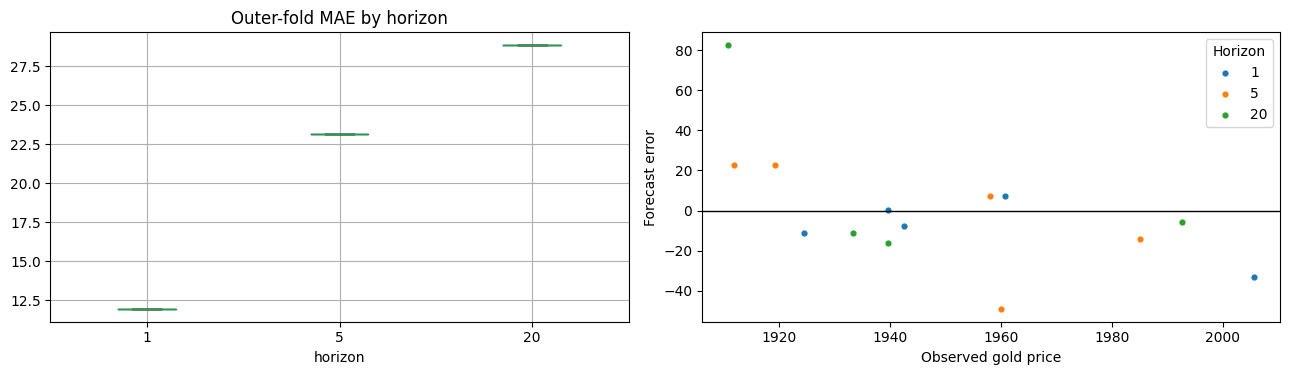

In [6]:
display(cv_metrics.groupby('horizon')[['MAE', 'RMSE', 'MAPE', 'MASE', 'skill_vs_persistence']].mean())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cv_metrics.boxplot(column='MAE', by='horizon', ax=axes[0])
axes[0].set_title('Outer-fold MAE by horizon')
for horizon, group in cv_predictions.groupby('horizon'):
    observed = group.dropna(subset=['actual'])
    axes[1].scatter(observed.actual, observed.prediction - observed.actual, s=12, label=str(horizon))
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_xlabel('Observed gold price')
axes[1].set_ylabel('Forecast error')
axes[1].legend(title='Horizon')
plt.suptitle('')
plt.tight_layout()

## 6. Lock the final configuration and evaluate the untouched holdout
The default is off so you can review development results first. Set
`final_holdout_enabled` to true in `config.json` when ready. This is an experiment guard,
not a request for additional permission. The function chooses parameters using development
history, records them before scoring, and preserves existing holdout results.

In [7]:
cfg = load_config()
if cfg['final_holdout_enabled']:
    holdout_predictions, holdout_metrics, locked_parameters = evaluate_holdout(
        KIND, panel, features, folds, cfg, trials=trials)
    display(holdout_metrics)
    display(locked_parameters)
else:
    print('Holdout not evaluated. Development predictions remain available for review.')

Holdout not evaluated. Development predictions remain available for review.


## 7. Refit the locked model and generate future forecasts
Run after the final holdout stage. The forecast starts from the latest observed gold quote.
Only the configured horizons are returned. Future actual external factors are not supplied.
Artifacts include the fitted model, input feature names, preprocessing where applicable,
locked configuration, predictions and metrics. No calibrated uncertainty intervals are claimed.

In [8]:
locked = ROOT / 'artifacts' / KIND / 'locked_parameters.json'
if cfg['final_holdout_enabled'] and locked.exists():
    future_forecast = refit_and_forecast(KIND, panel, features, cfg)
    display(future_forecast)
else:
    print('Final refit waits for the parameter-lock stage.')

Final refit waits for the parameter-lock stage.
